In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_context('notebook')
pd.set_option('float_format', '{:.3f}'.format)

№1

In [ ]:
events=pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)
print(events.shape)
print(events.iloc[:10, [2, 3, 4, 9, 12]])

(29710, 38)
         Date      Away Team       Home Team Remaining Time     Play Type
0  2026-04-19  Boston Bruins  Buffalo Sabres          20:00  period-start
1  2026-04-19  Boston Bruins  Buffalo Sabres          20:00       faceoff
2  2026-04-19  Boston Bruins  Buffalo Sabres          19:47           hit
3  2026-04-19  Boston Bruins  Buffalo Sabres          19:46           hit
4  2026-04-19  Boston Bruins  Buffalo Sabres          19:41           hit
5  2026-04-19  Boston Bruins  Buffalo Sabres          19:27           hit
6  2026-04-19  Boston Bruins  Buffalo Sabres          19:03           hit
7  2026-04-19  Boston Bruins  Buffalo Sabres          18:53   missed-shot
8  2026-04-19  Boston Bruins  Buffalo Sabres          18:48           hit
9  2026-04-19  Boston Bruins  Buffalo Sabres          18:37   missed-shot


№2
счет беру как максимум накпленного счета за игру. Число овертаймов определяю по последнему периоду, 3 значит основное время, 4 значит один овертайм, 5 значит два.

In [ ]:
games=events.groupby('Game ID')[['Date', 'Away Team', 'Home Team']].first()
games['Away Score']=events.groupby('Game ID')['Cumulated Away Score'].max()
games['Home Score']=events.groupby('Game ID')['Cumulated Home Score'].max()
def outcome(period):
    if period==3:
        return 'Final'
    elif period==4:
        return 'Final/OT'
    else:
        return 'Final/'+str(period-3)+'OT'
games['Outcome']=events.groupby('Game ID')['Period'].max().map(outcome)
print(games.columns)
print(games.iloc[-5:, -4:])

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='object')
                       Home Team  Away Score  Home Score    Outcome
Game ID                                                            
2025030412   Carolina Hurricanes           3           4   Final/OT
2025030413  Vegas Golden Knights           4           5  Final/2OT
2025030414  Vegas Golden Knights           5           3      Final
2025030415   Carolina Hurricanes           2           4      Final
2025030416  Vegas Golden Knights           3           0      Final


№3
Хозяева - гости (голы хозяев - голы гостей, исход, дата)

In [ ]:
def gameInfo(gameId):
    g= games.loc[gameId]
    return '%s - %s (%d - %d, %s, %s)' % (g['Home Team'], g['Away Team'], g['Home Score'], g['Away Score'], g['Outcome'], g['Date'])
print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


№4

In [ ]:
games['Total Score']=games['Away Score']+games['Home Score']
print(games['Total Score'].describe())

count   82.000
mean     5.927
std      2.260
min      1.000
25%      5.000
50%      6.000
75%      7.000
max     15.000
Name: Total Score, dtype: float64


№5

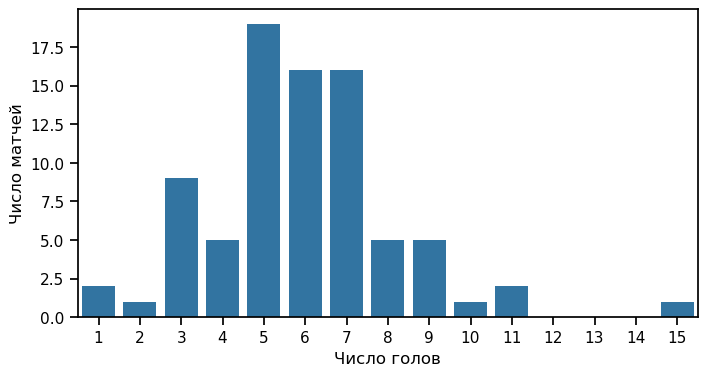

Total Score
1      2
2      1
3      9
4      5
5     19
6     16
7     16
8      5
9      5
10     1
11     2
15     1
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(8, 4))
sns.countplot(x=games['Total Score'], order=range(1, 16))
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.show()
print(games['Total Score'].value_counts().sort_index())

Чаще всего в матче забивают от 5 до 7 голов (51 матч из 82), самый частый результат 5 голов (19 матчей). Распределение несимметричное, так как справа есть редкие очень результативные матчи на 10, 11 и 15 голов, а слева значения быстро обрываются. Матчей без голов нет, минимум равен 1 голу. Таких матчей два, и оба закончились 1 - 0 в овертайме (пункт 6)

№6

In [ ]:
minscore = games[games['Total Score']==games['Total Score'].min()]
maxscore = games[games['Total Score']==games['Total Score'].max()]
print([gameInfo(i) for i in minscore.index])
print([gameInfo(i) for i in maxscore.index])

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


№7
Все поля с игроками на льду (вместе с вратарями) переведены в один столбец, пропуски и повторы внутри игры убираю и считаю, сколько осталось имен

In [ ]:
cols=(["Away Team's Player on the Ice #" + str(i) for i in range(1, 7)]+["Away Team's Goalie"]+["Home Team's Player on the Ice #" + str(i) for i in range(1, 7)]+["Home Team's Goalie"])
onice=pd.melt(events, id_vars=['Game ID'], value_vars=cols, value_name='Player').dropna()
onice=onice.drop_duplicates(['Game ID', 'Player'])
players=pd.DataFrame({'Game Info': games.index.map(gameInfo), 'Player Count': onice.groupby('Game ID').size()}, index=games.index)
print(players[players['Player Count']==players['Player Count'].max()])

                                                    Game Info  Player Count
Game ID                                                                    
2025030216  Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...            40


в примере в задани 41 игрок, у меня 40. Если не убирать пропуски NaN получается ровно 41, видимо в примере пустое значение посчитано как еще один игрок

№8
сначала определяю, в какие ворота бьет команда, если ворота хозяев слева, то хозяева бьют в правые ворота X = 89, а гости в левые X = -89. Если ворота хозяев справа, то наоборот. Потом считаю расстояние до ближайшей точки створа по формуле из задания

In [ ]:
shots=events['Play Type'].isin(['shot-on-goal','goal', 'missed-shot'])
home=events['Team Making the Play']==events['Home Team']
left=events["Home Team's Defending Side"]=='left'
X=np.where(home, np.where(left, 89, -89), np.where(left, -89, 89))
x=events['X Coordinate on the Ice Rink']
y=events['Y Coordinate on the Ice Rink']
d = np.where(y<-3, np.sqrt((x-X)**2+(y+3)**2), np.where(y > 3, np.sqrt((x-X)**2+(y-3)**2), np.abs(x-X)))
events['Shot Length']=np.where(shots, d, np.nan)
print(events[shots][['Game ID', 'Play Type', 'Shot Length']])

          Game ID     Play Type  Shot Length
7      2025030111   missed-shot       12.207
9      2025030111   missed-shot       12.000
12     2025030111   missed-shot       29.411
13     2025030111  shot-on-goal       62.169
19     2025030111   missed-shot       52.924
...           ...           ...          ...
29695  2025030416   missed-shot       54.083
29696  2025030416   missed-shot        5.099
29704  2025030416          goal       46.239
29706  2025030416   missed-shot       60.926
29707  2025030416  shot-on-goal       49.041

[7266 rows x 3 columns]


№9
Точные броски shot-on-goal и goal, неточные missed-shot. Чтобы сравнивать именно распределения, ставлю stat='density' и common_norm=False, тогда каждая группа нормируется отдельно

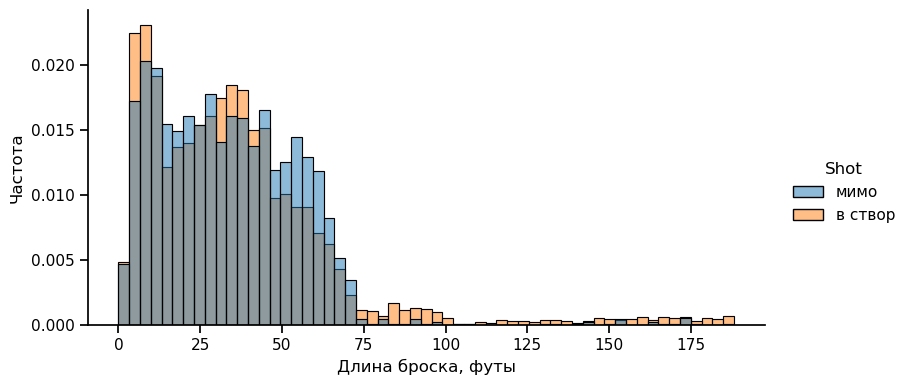

           count   mean    std   min    25%    50%    75%     max
Shot                                                             
в створ 4623.000 36.207 29.997 0.000 15.000 31.828 47.011 188.215
мимо    2643.000 34.014 22.313 0.000 16.155 32.249 49.041 185.068


In [ ]:
sh=events[shots].copy()
sh['Shot']=np.where(sh['Play Type']=='missed-shot', 'мимо', 'в створ')
sns.displot(data=sh, x='Shot Length',hue='Shot', stat='density',common_norm=False, height=4, aspect=2)
plt.xlabel('Длина броска, футы')
plt.ylabel('Частота')
plt.show()
print(sh.groupby('Shot')['Shot Length'].describe())

До 70-75 футов распределения похожи, и точные, и неточны броски в основном делают с расстояния до 60 футов. Точные броски немного чаще встречаются совсем рядом с воротами (до 10 футов), а мимо чаще бьют с 45-70 футов. Дальше 75 футов неточных бросков почти нет, а у точных остается длинный хвост до 188 футов, то есть броски из нейтральной зоны и со своей половины (89 футов это как раз расстояние от ворот до центральной линии)
Думаю, длинный хвост это броски в пустые ворота. По описанию данных вратаря на льду может не быть (поле вратаря тогда пустое). Если ворота пустые, можно бросать даже со своей половины, и в створ попасть легче

№10
незаблокированные броски shot-on-goal, goal и missed-shot

In [ ]:
sh['On Goal']=sh['Play Type']!='missed-shot'
numshots=sh.groupby(['Game ID','Team Making the Play'])['On Goal'].agg(['sum','count'])
numshots.columns=['Shots on Goal', 'Shots']
numshots['Share of Shots on Goal']=numshots['Shots on Goal']/numshots['Shots']
print(numshots['Share of Shots on Goal'])
print(numshots['Share of Shots on Goal'].describe())

Game ID     Team Making the Play
2025030111  Boston Bruins          0.625
            Buffalo Sabres         0.679
2025030112  Boston Bruins          0.614
            Buffalo Sabres         0.636
2025030113  Boston Bruins          0.694
                                    ... 
2025030414  Vegas Golden Knights   0.583
2025030415  Carolina Hurricanes    0.558
            Vegas Golden Knights   0.510
2025030416  Carolina Hurricanes    0.639
            Vegas Golden Knights   0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64
count   164.000
mean      0.639
std       0.085
min       0.353
25%       0.583
50%       0.639
75%       0.689
max       0.860
Name: Share of Shots on Goal, dtype: float64


В среднем в створ попадает около 64% незаблокированных бросков, примерно два броска из трех. У половины пар "игра-команда" доля лежит между 0.58 и 0.69, но разброс большой от 0.35 до 0.86. Точность бросков сильно меняется от матча к матчу, поэтому по одной игре трудно судить о команде

№11

In [ ]:
avgnumshots=numshots['Share of Shots on Goal'].groupby(level='Team Making the Play').mean()
print(avgnumshots.nlargest(5))
print(avgnumshots.nsmallest(5))

Team Making the Play
Edmonton Oilers       0.706
Philadelphia Flyers   0.684
Dallas Stars          0.670
Minnesota Wild        0.656
Colorado Avalanche    0.653
Name: Share of Shots on Goal, dtype: float64
Team Making the Play
Pittsburgh Penguins   0.554
Utah Mammoth          0.599
Carolina Hurricanes   0.615
Tampa Bay Lightning   0.626
Buffalo Sabres        0.626
Name: Share of Shots on Goal, dtype: float64


Средние доли у команд различаются не очень сильно, от 0.55 у Питтсбурга до 0.71 у Эдмонтона, у большинства команд от 0.6 до 0.7. Высокая точность не гарантирует успех, Каролина дошла до финала, но попала в пятерку худших. Зато в пункте 12 видно, что Каролина бросает в створ больше многих (31.6 за игру), то есть для нее важнее количество бросков, а не их точность

#12
Броски в створ считаю вместе с голами (shot-on-goal и goal), потому что гол это тоже бросок, попавший в створ. С таким подсчетом числа совпадают с примером
Если команда не забила в игре, у нее нет строки с голами, поэтому ставлю 0

In [ ]:
ongoal=events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
goals=events[events['Play Type']=='goal']
pergame=pd.DataFrame({'Shot': ongoal.groupby(['Game ID', 'Team Making the Play']).size(),'Goal': goals.groupby(['Game ID','Team Making the Play']).size()})
pergame=pergame.fillna(0)
avgshots=pergame.groupby(level='Team Making the Play').mean()
print(avgshots)

                       Shot  Goal
Team Making the Play             
Anaheim Ducks        31.667 3.250
Boston Bruins        25.167 2.000
Buffalo Sabres       30.462 3.308
Carolina Hurricanes  31.632 3.474
Colorado Avalanche   32.154 3.385
Dallas Stars         31.000 2.500
Edmonton Oilers      28.333 3.500
Los Angeles Kings    25.250 1.250
Minnesota Wild       28.727 3.727
Montréal Canadiens   23.263 2.842
Ottawa Senators      27.500 1.250
Philadelphia Flyers  24.600 2.100
Pittsburgh Penguins  26.500 1.833
Tampa Bay Lightning  28.000 2.143
Utah Mammoth         27.833 3.000
Vegas Golden Knights 26.545 3.455


#13

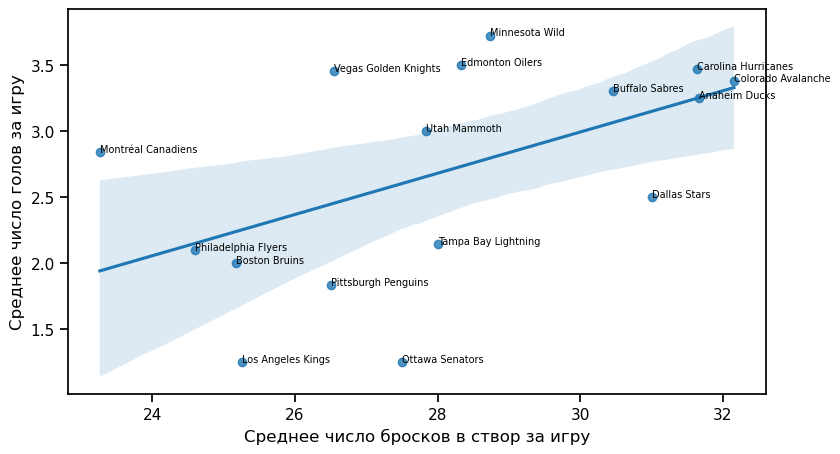

In [36]:
plt.figure(figsize=(9, 5))
sns.regplot(x='Shot', y='Goal', data=avgshots)
for team in avgshots.index:
    plt.annotate(team, (avgshots.loc[team, 'Shot'], avgshots.loc[team, 'Goal']), fontsize=7)
plt.xlabel('Среднее число бросков в створ за игру')
plt.ylabel('Среднее число голов за игру')
plt.show()

Связь видна, но слабая. Линия регрессии идет вверх, команды, которые чаще бросают в створ, в среднем больше забивают. Однко точки сильно разбросаны вокруг линии и доверительная область широкая. Например, Монреаль бросает меньше всех, но забивает 2.8 за игру, а Даллас бросает 31 раз за игру и забивает только 2.5. По 16 командам сильный вывод сделать нельзя

### 14. Матч с наибольшим числом бросков (включая промахи и заблокированные)

In [37]:
allshots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot'])]
allshots = allshots.groupby('Game ID').size()

idxmax = allshots.idxmax()
print(allshots.max())
print(gameInfo(idxmax))

208
Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


№15
Как в задании, в нечетных периодах меняю координаты на (-x, -y), тогда броски гостей идут в левые ворота, а хозяев в правые

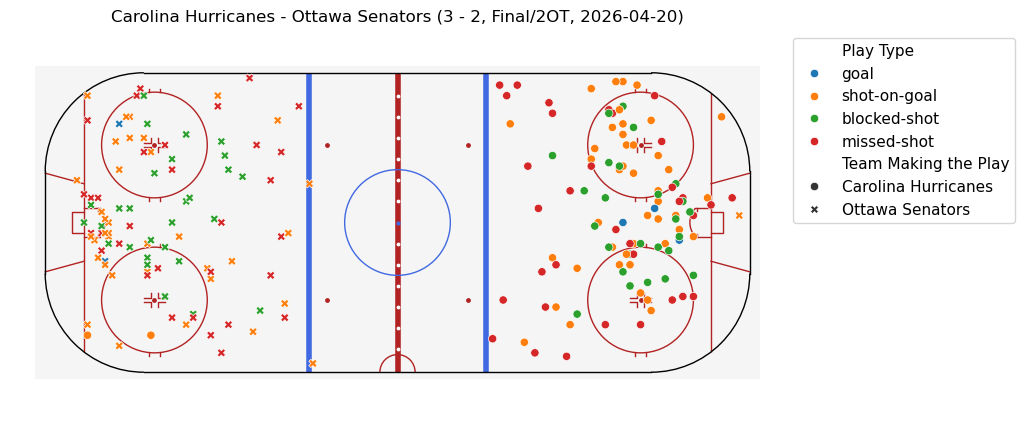

In [ ]:
from rink import plot_rink
game=events[(events['Game ID'] == idxmax) & events['Play Type'].isin(['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'])].copy()
odd = game['Period']%2==1
game.loc[odd, 'X Coordinate on the Ice Rink']=-game.loc[odd, 'X Coordinate on the Ice Rink']
game.loc[odd, 'Y Coordinate on the Ice Rink']=-game.loc[odd, 'Y Coordinate on the Ice Rink']
plt.figure(figsize=(10, 5))
plot_rink()
sns.scatterplot(data=game, x='X Coordinate on the Ice Rink', y='Y Coordinate on the Ice Rink', hue='Play Type', style='Team Making the Play', hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'])
plt.axis('equal')
plt.axis('off')
plt.title(gameInfo(idxmax))
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

№16

In [39]:
print(goals['Player in the Event #1'].value_counts().head(10))

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Jordan Staal         8
Nikolaj Ehlers       8
Nathan MacKinnon     7
Taylor Hall          7
Mark Stone           7
Jackson Blake        7
Name: count, dtype: int64


№17

In [ ]:
assists=pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']])
print(assists.value_counts().head(10))

Jack Eichel        20
Mitch Marner       19
Jackson Blake      13
Lane Hutson        13
Taylor Hall        12
Martin Necas       12
Nick Suzuki        12
Shea Theodore      12
Quinn Hughes       11
Kirill Kaprizov    11
Name: count, dtype: int64


№18

In [ ]:
points = pd.concat([goals['Player in the Event #1'], goals['Player in the Event #2'], goals['Player in the Event #3']])
print(points.value_counts().head(10))

Mitch Marner       29
Jack Eichel        22
Jackson Blake      20
Taylor Hall        19
Shea Theodore      18
Nikolaj Ehlers     18
Brett Howden       18
Logan Stankoven    16
Nick Suzuki        16
Pavel Dorofeyev    16
Name: count, dtype: int64


№19
число игр у игрока - в скольких матчах он был на льду

In [ ]:
games_played=onice['Player'].value_counts()
player_shots=ongoal['Player in the Event #1'].value_counts()
avg_player_shots=(player_shots/games_played).dropna()
print(avg_player_shots.sort_values(ascending=False).head(10))

Jason Robertson    5.000
Dylan Guenther     4.500
Nikita Kucherov    4.429
Matt Boldy         4.364
Quinton Byfield    4.250
Joel Eriksson Ek   4.000
Darren Raddysh     4.000
Alex Laferriere    3.750
David Pastrnak     3.667
Nathan MacKinnon   3.615
Name: count, dtype: float64


№20

In [ ]:
hits=events[events['Play Type']=='hit']['Player in the Event #1'].value_counts()
avg_hits=(hits/games_played).dropna()
print(avg_hits.sort_values(ascending=False).head(10))

Lawson Crouse        6.333
Alexander Petrovic   6.000
Alex Turcotte        6.000
Yakov Trenin         5.667
Dylan Cozens         5.500
Vasily Podkolzin     5.333
Marcus Foligno       5.000
Carl Grundstrom      5.000
Ivan Barbashev       5.000
Owen Tippett         4.833
Name: count, dtype: float64


№21
Гол пропускает вратарь команды, которая не забивала (по составу на льду в момент гола). У голов в овертайме в данных нет составов (0 игроков на льду), поэтому для них беру вратарей из предыдущего события. Если вратаря нет (пустые ворота), гол ни на кого не записывается

In [ ]:
gcols=["Away Team's Goalie", "Home Team's Goalie"]
ev=events.copy()
nodata=ev["# of Away Team's Players on the Ice"]==0
ev.loc[nodata, gcols]=ev[gcols].shift()[nodata]
g = ev[ev['Play Type']=='goal'].copy()
g['Goalie']=np.where(g['Team Making the Play']==g['Home Team'], g["Away Team's Goalie"], g["Home Team's Goalie"])
conceded=g.groupby(['Game ID', 'Goalie']).size()
goalies=pd.melt(ev, id_vars=['Game ID'], value_vars=gcols, value_name='Goalie').dropna()
goalies = goalies.drop_duplicates(['Game ID', 'Goalie']).set_index(['Game ID', 'Goalie'])
goalies['Conceded']=conceded
goalies['Conceded']=goalies['Conceded'].fillna(0)
shutouts = goalies[goalies['Conceded']==0]
print(shutouts['Conceded'])
print(sorted(shutouts.index.get_level_values('Goalie').unique()))

Game ID     Goalie            
2025030126  Andrei Vasilevskiy   0.000
2025030142  Dan Vladar           0.000
2025030314  Frederik Andersen    0.000
2025030416  Brandon Bussi        0.000
2025030114  Joonas Korpisalo     0.000
2025030131  Frederik Andersen    0.000
2025030146  Dan Vladar           0.000
2025030221  Frederik Andersen    0.000
2025030235  Scott Wedgewood      0.000
Name: Conceded, dtype: float64
['Andrei Vasilevskiy', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Joonas Korpisalo', 'Scott Wedgewood']


№22
Есть ли в этом плей-офф преимущество домашней площадки? Для этого смотрю какую долю матчей выиграли хозяева и сколько в среднем забивали хозяева и гости

In [ ]:
home_win=games['Home Score']>games['Away Score']
print(home_win.sum(),'побед хозяев из', len(games))
print(home_win.mean())
print(games[['Home Score', 'Away Score']].mean())

39 побед хозяев из 82
0.47560975609756095
Home Score   2.805
Away Score   3.122
dtype: float64


Преимущества домашней площадки в этом плей-офф не видно. Хозяева выиграли 39 матчей из 82 (47.6%), то есть меньше половины, и в среднем забвали меньше гостей: 2.81 гола против 3.12.